In [1]:
import shap
import pandas as pd
import xgboost as xgb
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split


c:\Users\jvesc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
df = pd.read_csv('../../../datasets/balanceados/dataset_total_balanceado.csv')
drop_columns = ['Fwd Packet Length Min', 'Average Packet Size', 'Packet Length Std', 'Packet Length Mean']
df.drop(columns=drop_columns, inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 59 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Mean       104802 non-null  float64
 6   Fwd Packet Length Std        104802 non-null  float64
 7   Bwd Packet Length Max        104802 non-null  float64
 8   Bwd Packet Length Min        104802 non-null  float64
 9   Bwd Packet Length Mean       104802 non-null  float64
 10  Bwd Packet Length Std        104802 non-null  float64
 11  Flow Bytes/s                 104802 non-null  float64
 12  Flow Packets/s               104802 non-null  float64
 13  Flow IAT M

In [8]:
x=df.drop(columns=['Label'])
y=df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)

DT

In [9]:
modelo_dt = tree.DecisionTreeClassifier(random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
matriz_dt1 = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    matriz_dt1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 1.0000
Acurácia:  99.9618
Precisão:  99.9618
Recall:    99.9618
F1-Score:  99.9618

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.96%                0.04%
Real: 1 (Ataque)                0.04%               99.96%


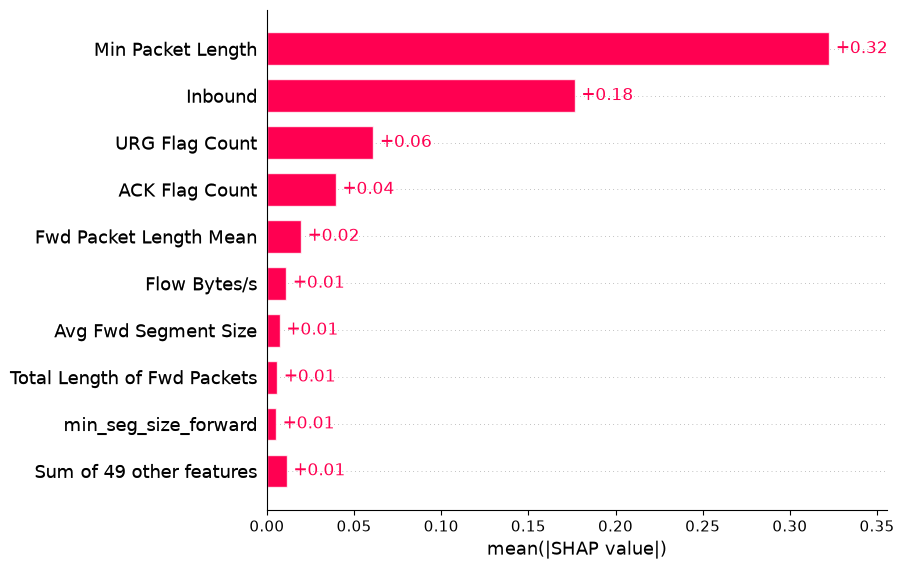

In [10]:
explainer = shap.TreeExplainer(modelo_dt)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values[:, :, 1])

DT

In [11]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 1.0000
Acurácia:  99.9571
Precisão:  99.9570
Recall:    99.9572
F1-Score:  99.9571

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.97%                0.03%
Real: 1 (Ataque)                0.06%               99.94%


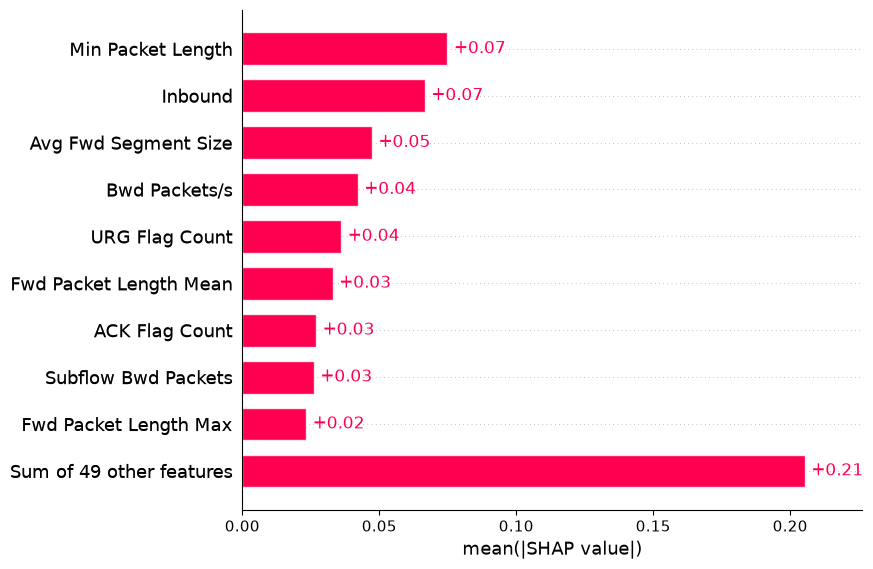

In [12]:
explainer = shap.TreeExplainer(modelo_rf)
shap_values = explainer(amostra_500)        

shap.plots.bar(shap_values[:, :, 1])

XGB

In [14]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 1.0000
Acurácia:  99.9618
Precisão:  99.9619
Recall:    99.9618
F1-Score:  99.9618

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.95%                0.05%
Real: 1 (Ataque)                0.03%               99.97%


In [ ]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9876
Acurácia:  98.6833
Precisão:  98.6965
Recall:    98.6780
F1-Score:  98.6830

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.01%                1.99%
Real: 1 (Ataque)                0.65%               99.35%


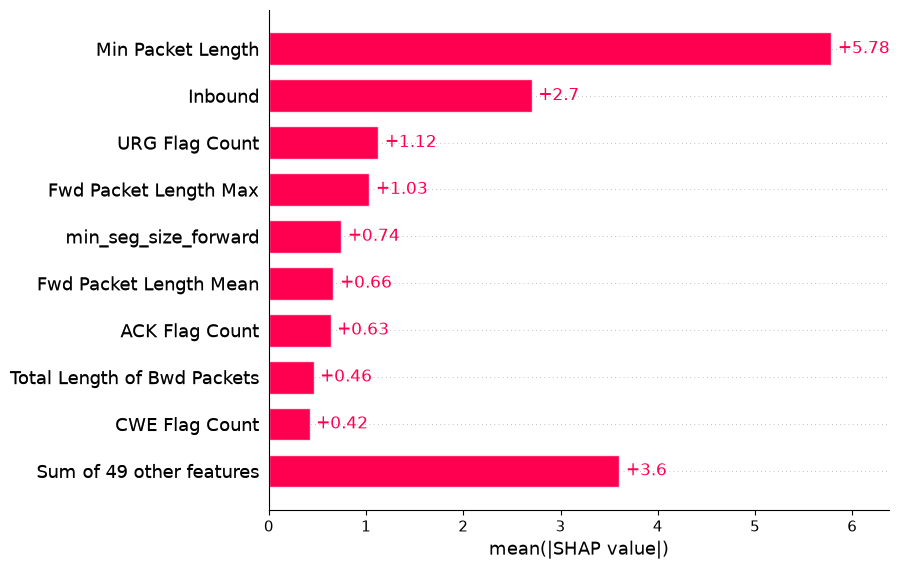

In [15]:
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)

SVM

In [16]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9979
Acurácia:  99.8664
Precisão:  99.8673
Recall:    99.8657
F1-Score:  99.8664

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.77%                0.23%
Real: 1 (Ataque)                0.04%               99.96%


Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


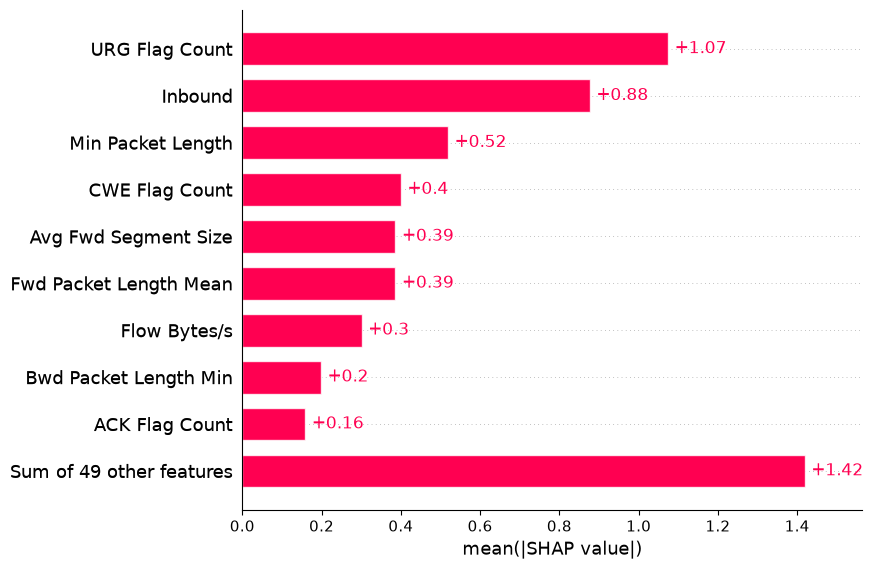

In [17]:
explainer = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)    

KNN

In [18]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9996
Acurácia:  99.9237%
Precisão:  99.9233%
Recall:    99.9240%
F1-Score:  99.9237%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.97%                0.03%
Real: 1 (Ataque)                0.12%               99.88%


PermutationExplainer explainer: 101it [04:00,  2.43s/it]                         


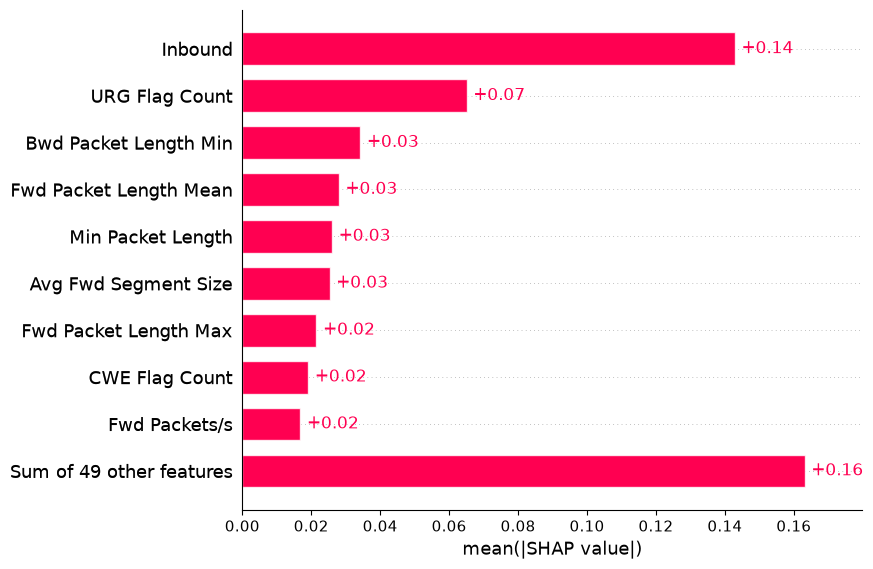

In [19]:
explainer = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:,:, 1])

MLP

In [ ]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9997
Acurácia:  99.9618
Precisão:  99.9616
Recall:    99.9621
F1-Score:  99.9618

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.99%                0.01%
Real: 1 (Ataque)                0.07%               99.93%


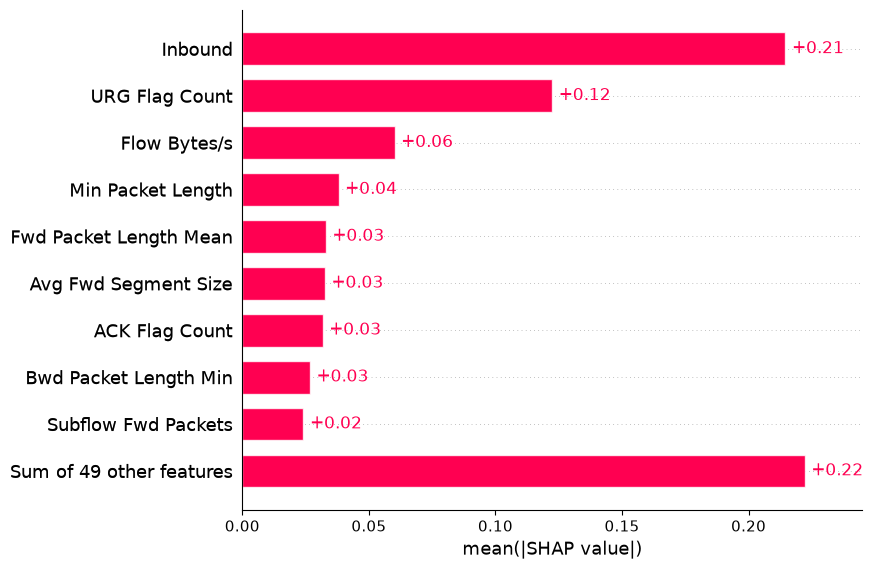

In [21]:
explainer = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:, :, 1])

Rodada 3

'Min Packet Length', 'Inbound'

In [22]:
df2 = df
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 59 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Mean       104802 non-null  float64
 6   Fwd Packet Length Std        104802 non-null  float64
 7   Bwd Packet Length Max        104802 non-null  float64
 8   Bwd Packet Length Min        104802 non-null  float64
 9   Bwd Packet Length Mean       104802 non-null  float64
 10  Bwd Packet Length Std        104802 non-null  float64
 11  Flow Bytes/s                 104802 non-null  float64
 12  Flow Packets/s               104802 non-null  float64
 13  Flow IAT M

In [23]:
dropar2 = ['Min Packet Length', 'Inbound']
df2.drop(columns=dropar2, inplace=True)
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 57 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Mean       104802 non-null  float64
 6   Fwd Packet Length Std        104802 non-null  float64
 7   Bwd Packet Length Max        104802 non-null  float64
 8   Bwd Packet Length Min        104802 non-null  float64
 9   Bwd Packet Length Mean       104802 non-null  float64
 10  Bwd Packet Length Std        104802 non-null  float64
 11  Flow Bytes/s                 104802 non-null  float64
 12  Flow Packets/s               104802 non-null  float64
 13  Flow IAT M

In [24]:
x2=df2.drop(columns=['Label'])
y2=df2['Label']

x_treino2, x_teste2, y_treino2, y_teste2 = train_test_split(x2, y2, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled2 = scaler.fit_transform(x_treino2)   
x_teste_scaled2 = scaler.transform(x_teste2)

amostra2_500 = x_teste_scaled2.sample(n=500, random_state=42)
amostra2_100 = x_teste_scaled2.sample(n=100, random_state=42)

In [25]:
modelo_dt2 = tree.DecisionTreeClassifier(random_state=42)
modelo_dt2.fit(x_treino_scaled2, y_treino2)
y_pred_dt2 = modelo_dt2.predict(x_teste_scaled2)
y_pred_dttreino2 = modelo_dt2.predict(x_treino_scaled2)

acuracia_treino2 = accuracy_score(y_treino2, y_pred_dttreino2)
print(f"Acurácia no conjunto de treino: {acuracia_treino2:.4f}")

acuracia = accuracy_score(y_teste2, y_pred_dt2)
precisao = precision_score(y_teste2, y_pred_dt2, average='macro')
recall = recall_score(y_teste2, y_pred_dt2, average='macro')
f1 = f1_score(y_teste2, y_pred_dt2, average='macro')
matriz_dt2 = confusion_matrix(y_teste2, y_pred_dt2)

matriz_confusao_dt2 = pd.DataFrame(
    matriz_dt2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt2 = matriz_confusao_dt2.div(matriz_confusao_dt2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt2 )*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9999
Acurácia:  99.8998
Precisão:  99.9000
Recall:    99.8996
F1-Score:  99.8998

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.87%                0.13%
Real: 1 (Ataque)                0.08%               99.92%


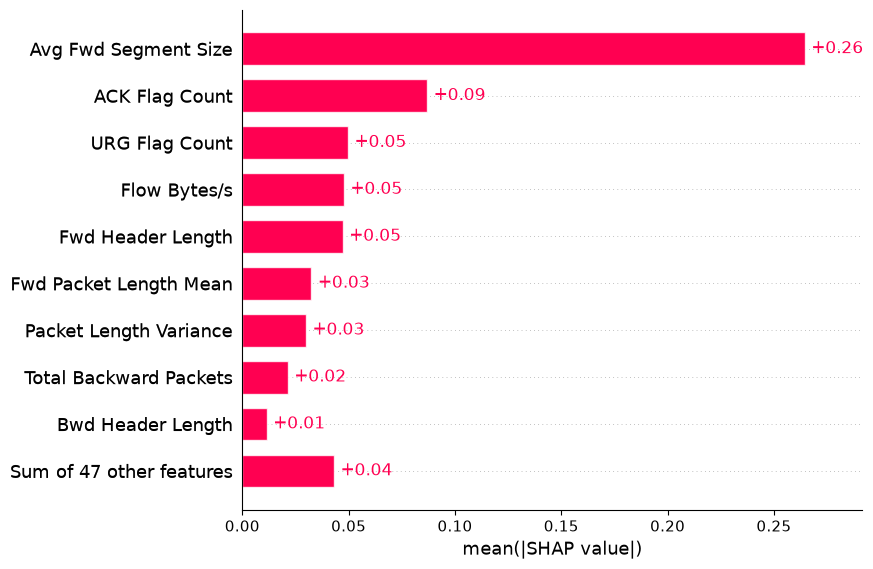

In [26]:
explainer = shap.TreeExplainer(modelo_dt2)
shap_values = explainer(amostra2_500)

shap.plots.bar(shap_values[:, :, 1])

RF

In [27]:
modelo_rf2 = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf2.fit(x_treino_scaled2, y_treino2)
y_pred_rf2 = modelo_rf2.predict(x_teste_scaled2)
y_pred_rftreino2 = modelo_rf2.predict(x_treino_scaled2)

acuracia_treino2 = accuracy_score(y_treino2, y_pred_rftreino2)
print(f"Acurácia no conjunto de treino: {acuracia_treino2:.4f}")

acuracia_rf2 = accuracy_score(y_teste2, y_pred_rf2)
precisao_rf2 = precision_score(y_teste2, y_pred_rf2, average='macro')
recall_rf2 = recall_score(y_teste2, y_pred_rf2, average='macro')
f1_rf2 = f1_score(y_teste2, y_pred_rf2, average='macro')
matriz_rf2 = confusion_matrix(y_teste2, y_pred_rf2)

matriz_confusao_rf2 = pd.DataFrame(
    matriz_rf2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf2 = matriz_confusao_rf2.div(matriz_confusao_rf2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf2*100):.4f}")
print(f"Precisão:  {(precisao_rf2*100):.4f}")
print(f"Recall:    {(recall_rf2*100):.4f}")
print(f"F1-Score:  {(f1_rf2*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf2)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9999
Acurácia:  99.9380
Precisão:  99.9379
Recall:    99.9380
F1-Score:  99.9380

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.94%                0.06%
Real: 1 (Ataque)                0.07%               99.93%


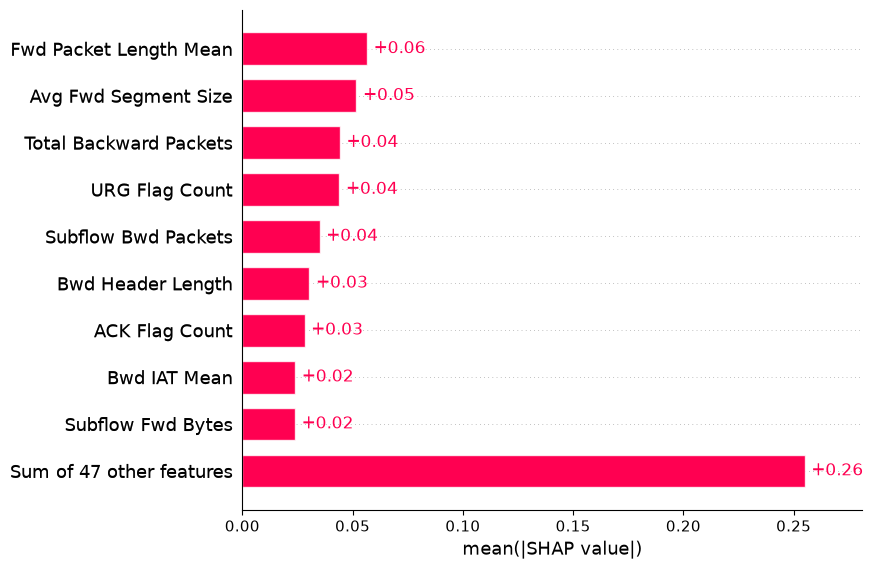

In [28]:
explainer = shap.TreeExplainer(modelo_rf2)
shap_values = explainer(amostra2_500)        

shap.plots.bar(shap_values[:, :, 1])

XGB

In [29]:
modelo_xgb2 = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb2.fit(x_treino_scaled2, y_treino2)
y_pred_xgb2 = modelo_xgb2.predict(x_teste_scaled2)
y_pred_xgb2treino = modelo_xgb2.predict(x_treino_scaled2)

acuracia_treino = accuracy_score(y_treino2, y_pred_xgb2treino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb2 = accuracy_score(y_teste2, y_pred_xgb2)
precisao_xgb2 = precision_score(y_teste2, y_pred_xgb2, average='macro')
recall_xgb2 = recall_score(y_teste2, y_pred_xgb2, average='macro')
f1_xgb2 = f1_score(y_teste2, y_pred_xgb2, average='macro')
matriz_xgb2 = confusion_matrix(y_teste2, y_pred_xgb2 )

matriz_confusao_xgb2 = pd.DataFrame(
    matriz_xgb2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb2 = matriz_confusao_xgb2.div(matriz_confusao_xgb2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb2*100):.4f}")
print(f"Precisão:  {(precisao_xgb2*100):.4f}")
print(f"Recall:    {(recall_xgb2*100):.4f}")
print(f"F1-Score:  {(f1_xgb2*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb2)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9999
Acurácia:  99.9380
Precisão:  99.9380
Recall:    99.9379
F1-Score:  99.9380

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.93%                0.07%
Real: 1 (Ataque)                0.06%               99.94%


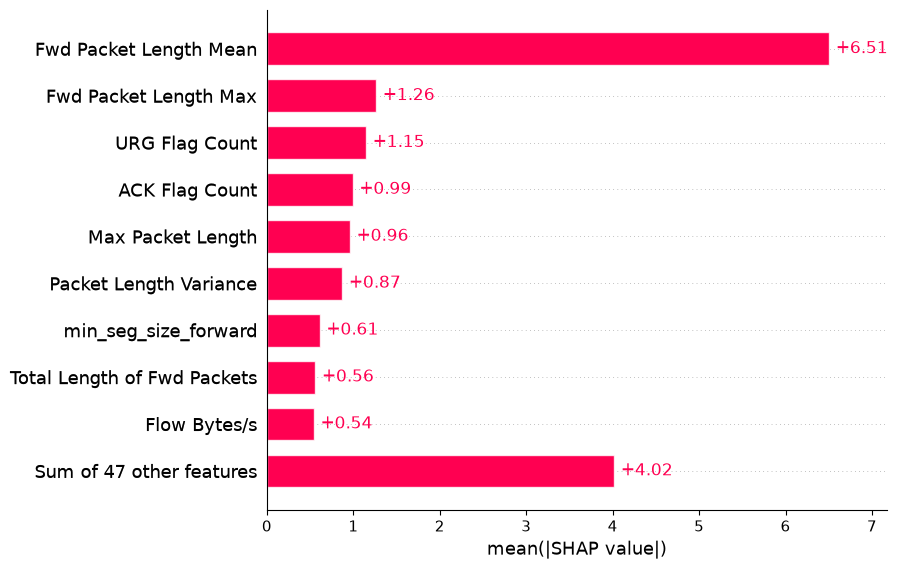

In [30]:
explainer = shap.TreeExplainer(modelo_xgb2)
shap_values = explainer(amostra2_500)

shap.plots.bar(shap_values)

SVM

In [31]:
modelo_svm2 = LinearSVC(random_state=42, max_iter=2000);
modelo_svm2.fit(x_treino_scaled2, y_treino2)
y_pred_svm2 = modelo_svm2.predict(x_teste_scaled2)
y_pred_svmtreino2 = modelo_svm2.predict(x_treino_scaled2)

acuracia_treino2 = accuracy_score(y_treino2, y_pred_svmtreino2)
print(f"Acurácia no conjunto de treino: {acuracia_treino2:.4f}")

acuracia_svm2 = accuracy_score(y_teste2, y_pred_svm2)
precisao_svm2 = precision_score(y_teste2, y_pred_svm2, average='macro')
recall_svm2 = recall_score(y_teste2, y_pred_svm2, average='macro')
f1_svm2 = f1_score(y_teste2, y_pred_svm2, average='macro')
matriz_svm2 = confusion_matrix(y_teste2, y_pred_svm2)

matriz_confusao_svm2 = pd.DataFrame(
    matriz_svm2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm2 = matriz_confusao_svm2.div(matriz_confusao_svm2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm2*100):.4f}")
print(f"Precisão:  {(precisao_svm2*100):.4f}")
print(f"Recall:    {(recall_svm2*100):.4f}")
print(f"F1-Score:  {(f1_svm2*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm2)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9954
Acurácia:  99.6136
Precisão:  99.6139
Recall:    99.6132
F1-Score:  99.6135

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.57%                0.43%
Real: 1 (Ataque)                0.34%               99.66%


Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


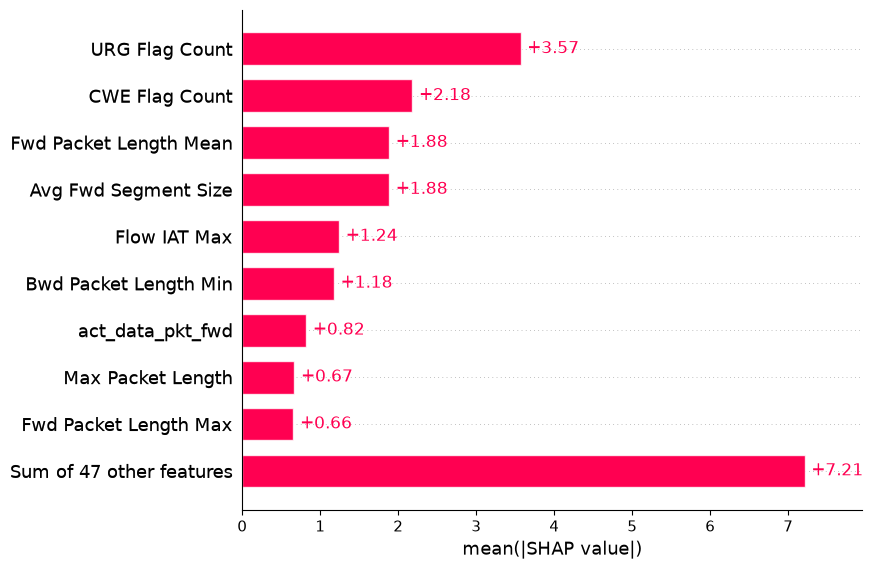

In [32]:
explainer = shap.LinearExplainer(modelo_svm2, x_treino_scaled2)
shap_values = explainer(amostra2_500)

shap.plots.bar(shap_values)    

KNN

In [33]:
modelo_knn2 = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn2.fit(x_treino_scaled2, y_treino2)
y_pred_knn2 = modelo_knn2.predict(x_teste_scaled2)
y_pred_knntreino2 = modelo_knn2.predict(x_treino_scaled2)

acuracia_treino2 = accuracy_score(y_treino2, y_pred_knntreino2)
print(f"Acurácia no conjunto de treino: {acuracia_treino2:.4f}")

acuracia_knn2 = accuracy_score(y_teste2, y_pred_knn2)
precisao_knn2 = precision_score(y_teste2, y_pred_knn2, average='macro')
recall_knn2 = recall_score(y_teste2, y_pred_knn2, average='macro')
f1_knn2 = f1_score(y_teste2, y_pred_knn2, average='macro')
matriz_knn2 = confusion_matrix(y_teste2, y_pred_knn2)

matriz_confusao_knn2 = pd.DataFrame(
    matriz_knn2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn2 = matriz_confusao_knn2.div(matriz_confusao_knn2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn2*100):.4f}%")
print(f"Precisão:  {(precisao_knn2*100):.4f}%")
print(f"Recall:    {(recall_knn2*100):.4f}%")
print(f"F1-Score:  {(f1_knn2*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn2)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9992
Acurácia:  99.8664%
Precisão:  99.8663%
Recall:    99.8666%
F1-Score:  99.8664%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.88%                0.12%
Real: 1 (Ataque)                0.15%               99.85%


PermutationExplainer explainer: 101it [04:29,  2.87s/it]                         


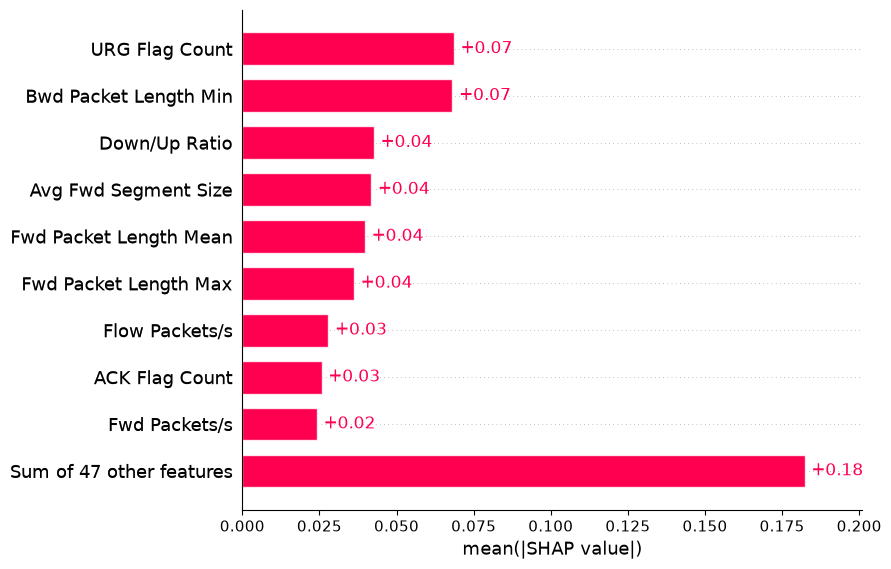

In [34]:
explainer = shap.PermutationExplainer(modelo_knn2.predict_proba,shap.sample(x_treino_scaled2, 50, random_state=42))
shap_values = explainer(amostra2_100)

shap.plots.bar(shap_values[:,:, 1])

MLP

In [35]:
modelo_mlp2 = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp2.fit(x_treino_scaled2, y_treino2)
y_pred_mlp2 = modelo_mlp2.predict(x_teste_scaled2)
y_pred_mlptreino2 = modelo_mlp2.predict(x_treino_scaled2)

acuracia_treino2 = accuracy_score(y_treino2, y_pred_mlptreino2)
print(f"Acurácia no conjunto de treino: {acuracia_treino2:.4f}")

acuracia_mlp2 = accuracy_score(y_teste2, y_pred_mlp2)
precisao_mlp2 = precision_score(y_teste2, y_pred_mlp2, average='macro')
recall_mlp2 = recall_score(y_teste2, y_pred_mlp2, average='macro')
f1_mlp2 = f1_score(y_teste2, y_pred_mlp2, average='macro')
matriz_mlp2 = confusion_matrix(y_teste2, y_pred_mlp2)

matriz_confusao_mlp2 = pd.DataFrame(
    matriz_mlp2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp2 = matriz_confusao_mlp2.div(matriz_confusao_mlp2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp2*100):.4f}")
print(f"Precisão:  {(precisao_mlp2*100):.4f}")
print(f"Recall:    {(recall_mlp2*100):.4f}")
print(f"F1-Score:  {(f1_mlp2*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp2)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9992
Acurácia:  99.8998
Precisão:  99.8997
Recall:    99.8999
F1-Score:  99.8998

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.91%                0.09%
Real: 1 (Ataque)                0.11%               99.89%


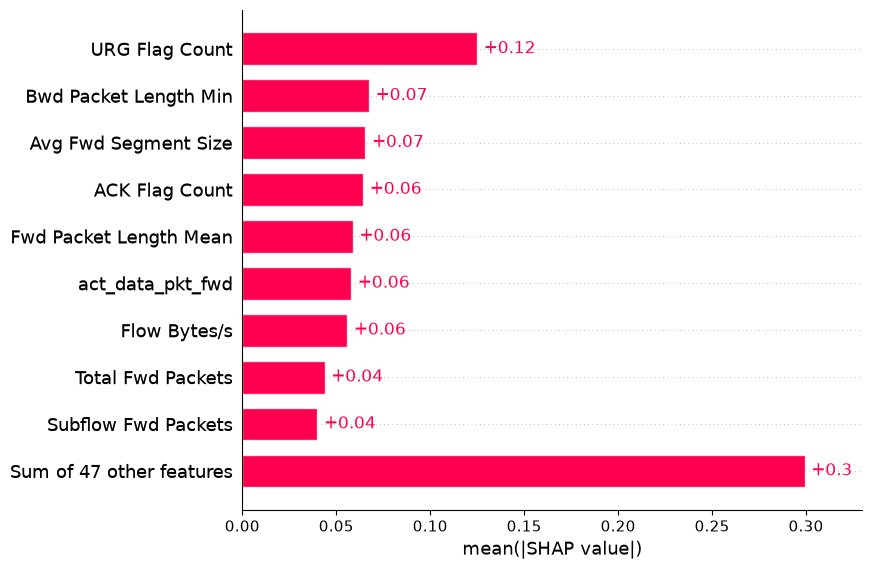

In [36]:
explainer = shap.PermutationExplainer(modelo_mlp2.predict_proba,shap.sample(x_treino_scaled2, 50, random_state=42))
shap_values = explainer(amostra2_100)

shap.plots.bar(shap_values[:, :, 1])